In [145]:
import pandas as pd
import duckdb
import seaborn as sns
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

### Предметная область

Обезличенные данные о клиентах банка. Одна строка - один клиент.

Удержать клиента дешевле, чем привлечь нового, поэтому цель анализа - выявить тех, кто уходит, и предложить решение этой проблемы.

Для начала работы загрузим датасет

In [146]:
df = pd.read_csv("../data/Customer-Churn-Records.csv")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [147]:
df.shape

(10000, 18)

Размер датасета - 10 000 строк и 18 столбцов.

### Описание полей

In [148]:
df.dtypes

RowNumber               int64
CustomerId              int64
Surname                   str
CreditScore             int64
Geography                 str
Gender                    str
Age                     int64
Tenure                  int64
Balance               float64
NumOfProducts           int64
HasCrCard               int64
IsActiveMember          int64
EstimatedSalary       float64
Exited                  int64
Complain                int64
Satisfaction Score      int64
Card Type                 str
Point Earned            int64
dtype: object



| Столбец | Описание |
|---|---|
| `CreditScore` | Кредитный рейтинг (чем выше, тем надёжнее клиент) |
| `Geography` | Страна (Франция, Германия, Испания) |
| `Gender` | Пол |
| `Age` | Возраст |
| `Tenure` | Сколько лет клиент с банком |
| `Balance` | Остаток на счёте |
| `NumOfProducts` | Сколько продуктов банка у клиента (карта, вклад, кредит…) |
| `HasCrCard` | Есть ли кредитная карта (1 - да, 0 - нет) |
| `IsActiveMember` | Активно ли клиент пользуется банком (1 - да, 0 - нет) |
| `EstimatedSalary` | Примерная зарплата |
| `Complain` | Была ли жалоба (1 - да, 0 - нет) |
| `Satisfaction Score` | Оценка удовлетворённости (1-5) |
| `Card Type` | Тип карты (Silver, Gold, Platinum, Diamond) |
| `Point Earned` | Баллы программы лояльности |
| `Exited` | **Ушёл ли клиент (1 - ушёл, 0 - остался) - целевая переменная** |

In [149]:
df['Exited'].value_counts(normalize=True)

Exited
0    0.7962
1    0.2038
Name: proportion, dtype: float64

Из банка ушло 20% клиентов. Классы несбалансированы, это нужно учитывать при сравнении групп.

In [150]:
df['Geography'].value_counts(normalize=True)

Geography
France     0.5014
Germany    0.2509
Spain      0.2477
Name: proportion, dtype: float64

Половина клиентов из Франции, остальная половина из Германии и Испании.

In [151]:
df.isna().sum().sum()

np.int64(0)

В датасете нет пропусков.

In [152]:
df.duplicated().sum()

np.int64(0)

В датасете нет дубликатов.

In [153]:
df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

Удалили неинформативные столбцы.

In [154]:
df.describe()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Point Earned
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203800,0.204400,3.013800,606.515100
std,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402842,0.403283,1.405919,225.924839
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000,0.000000,1.000000,119.000000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000,0.000000,2.000000,410.000000
50%,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000,0.000000,3.000000,605.000000
75%,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000,0.000000,4.000000,801.000000
max,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000,1.000000,5.000000,1000.000000


Возраст клиентов от 18 до 92 лет, медиана - 37 лет.

Не менее 25% клиентов имеют нулевые балансы, возможно, это «спящие» счета, поэтому проверим их отток отдельно.

Большинство клиентов имеют кредитную карту.

Большинство клиентов имеют 1-2 продукта банка.

Активных клиентов - 51%.

20% клиентов оставили жалобу на банк.

Средняя оценка удовлетворённости банком - 3.

Сформируем гипотезы:

**1. Гипотеза:** клиенты с несколькими продуктами уходят реже.\
*Обоснование:* большое количество продуктов формирует привязанность к банку.\
*В случае подтверждения:* предложить использование кросс-продаж.

**2. Гипотеза:** неактивные клиенты уходят чаще.\
*Обоснование:* возможно, они уже готовятся к полному переходу в другой банк.\
*В случае подтверждения:* предложить программы реактивации.

**3. Гипотеза:** чем выше статус карты, тем ниже отток.\
*Обоснование:* премиальные карты дают больше привилегий, которые сжигаются при переходе в другой банк.\
*В случае подтверждения:* предложить улучшить систему апгрейдов карты для удержания клиентов.

**4. Гипотеза:** отток различается у мужчин и женщин.\
*Обоснование:* проверим, есть ли различия в поведении сегментов.\
*В случае подтверждения:* учитывать пол при сегментации клиентов.

**5. Гипотеза:** клиенты младше 37 лет (медианный возраст) уходят чаще.\
*Обоснование:* молодым легче переключаться между банками.\
*В случае подтверждения:* предложить таргетированные по возрасту предложения.

**6. Гипотеза:** клиенты, которые удовлетворены банком на 1 или 2 балла, уходят чаще.\
*Обоснование:* клиенты уходят из-за недовольства банком.\
*В случае подтверждения:* в первую очередь работать с недовольными клиентами, которые ещё не ушли.

### SQL

Выводы предварительные, статистическую значимость проверим позже.

**Гипотеза 1**

Проверим гипотезу о том, что клиенты с несколькими продуктами уходят реже, написав запрос с использованием GROUP BY по количеству продуктов.

In [155]:
query = """
SELECT NumOfProducts AS products, COUNT(*) AS clients, ROUND(AVG(Exited) * 100, 2) AS churn_percent
FROM df
GROUP BY products
ORDER BY products
"""
products_churn = duckdb.sql(query).df()
products_churn

,products,clients,churn_percent
0,1,5084,27.71
1,2,4590,7.60
2,3,266,82.71
3,4,60,100.00


Гипотеза подтверждается частично, у клиентов с двумя продуктами отток на 20,1 процентного пункта ниже, чем у клиентов с одним продуктом, однако видно, что клиенты, которые имеют 3 и 4 продукта, уходят аномально часто, 82,71% и 100% оттока соответственно.

**Гипотеза 2**

Проверим гипотезу о том, что неактивные клиенты уходят чаще, написав запрос с использованием GROUP BY по бинарному полю IsActiveMember.

In [156]:
query = """
SELECT CASE WHEN IsActiveMember = 1 THEN 'active' ELSE 'not_active' END AS active, COUNT(*) AS clients, ROUND(AVG(Exited) * 100, 2) AS churn_percent
FROM df
GROUP BY active
ORDER BY active
"""
activity_churn = duckdb.sql(query).df()
activity_churn

,active,clients,churn_percent
0,active,5151,14.27
1,not_active,4849,26.87


Гипотеза подтверждается, так как мы можем увидеть, что неактивные клиенты уходят почти в 2 раза чаще, чем активные.

**Гипотеза 3**

Проверим гипотезу о том, что чем выше статус карты, тем реже уходят клиенты, написав запрос с использованием GROUP BY по типам карты.

In [157]:
query = """
SELECT "Card Type" AS card_type, COUNT(*) AS clients, ROUND(AVG(Exited) * 100, 2) AS churn_percent
FROM df
GROUP BY card_type
ORDER BY CASE WHEN card_type = 'SILVER' THEN 1
              WHEN card_type = 'GOLD' THEN 2
              WHEN card_type = 'PLATINUM' THEN 3
              WHEN card_type = 'DIAMOND' THEN 4 END
"""
duckdb.sql(query).df()

,card_type,clients,churn_percent
0,SILVER,2496,20.11
1,GOLD,2502,19.26
2,PLATINUM,2495,20.36
3,DIAMOND,2507,21.78


Гипотеза не подтверждается, так как отток клиентов по типу карты отличается несущественно. Отток во всех группах 19-22 процента.

**Гипотеза 4**

Проверим гипотезу о том, что отток клиентов различается у женщин и мужчин, написав запрос с использованием GROUP BY по гендеру.

In [158]:
query = """
SELECT Gender AS gender, COUNT(*) AS clients, ROUND(AVG(Exited) * 100, 2) AS churn_percent
FROM df
GROUP BY gender
ORDER BY churn_percent
"""
duckdb.sql(query).df()

,gender,clients,churn_percent
0,Male,5457,16.47
1,Female,4543,25.07


Гипотеза подтверждается, можем наблюдать, что отток у женщин на 8,6 процентного пункта больше, чем у мужчин.

**Гипотеза 5**

Проверим гипотезу о том, что у молодых клиентов до 37 лет отток клиентов больше, чем у взрослых. Напишем запрос, используя UNION ALL, чтобы не тратить время на проверку дубликатов, так как условия WHERE не пересекаются и дубликатов быть не может.

In [159]:
query = """
SELECT COUNT(*) AS clients, MIN(Age) AS min_age, MAX(Age) AS max_age, ROUND(AVG(Exited) * 100, 2) AS churn_percent
FROM df
WHERE Age < 37
UNION ALL
SELECT COUNT(*) AS clients, MIN(Age) AS min_age, MAX(Age) AS max_age, ROUND(AVG(Exited) * 100, 2) AS churn_percent
FROM df
WHERE Age >= 37
ORDER BY min_age
"""
duckdb.sql(query).df()

,clients,min_age,max_age,churn_percent
0,4609,18,36,8.68
1,5391,37,92,30.38


Гипотеза не подтверждается, эффект обратный. У клиентов от 37 лет отток на 21,7 процентного пункта больше, чем у молодых.

Тут же проверим отток по возрастным группам, разбив на них клиентов, пользуясь CASE WHEN.

In [160]:
query = """
SELECT CASE WHEN Age <= 27 THEN '18 - 27'
            WHEN Age <= 37 THEN '28 - 37'
            WHEN Age <= 47 THEN '38 - 47'
            WHEN Age <= 57 THEN '48 - 57'
            ELSE '58+' END AS age_group,
       COUNT(*) AS clients, ROUND(AVG(Exited) * 100, 2) AS churn_percent
FROM df
GROUP BY age_group
ORDER BY age_group
"""
age_group_churn = duckdb.sql(query).df()
age_group_churn

,age_group,clients,churn_percent
0,18 - 27,1020,7.16
1,28 - 37,4067,9.56
2,38 - 47,3203,24.57
3,48 - 57,1055,55.26
4,58+,655,31.45


Заметим, что наибольший отток у возрастной группы 48 - 57 лет. Отток растёт до 55% к 48-57 годам, а после 58 лет снижается.

**Гипотеза 6**

Проверим гипотезу о том, что клиенты, которые не удовлетворены банком (оценка 1-2), уходят чаще, чем удовлетворенные клиенты (оценка 3-5), разбив клиентов на две группы с помощью CASE WHEN.

In [161]:
query = """
SELECT CASE WHEN "Satisfaction Score" BETWEEN 1 AND 2 THEN '1 - 2' ELSE '3 - 5' END AS satisfaction, COUNT(*) AS clients, ROUND(AVG(Exited) * 100, 2) AS churn_percent
FROM df
GROUP BY satisfaction
ORDER BY satisfaction
"""
duckdb.sql(query).df()

,satisfaction,clients,churn_percent
0,1 - 2,3946,20.93
1,3 - 5,6054,20.02


Гипотеза не подтверждается, так как отток у неудовлетворенных и удовлетворенных клиентов примерно одинаковый.

Посмотрим также на отток по каждой оценке удовлетворенности, написав запрос с использованием GROUP BY.

In [162]:
query = """
SELECT "Satisfaction Score" AS satisfaction, COUNT(*) AS clients, ROUND(AVG(Exited) * 100, 2) AS churn_percent
FROM df
GROUP BY satisfaction
ORDER BY satisfaction
"""
duckdb.sql(query).df()

,satisfaction,clients,churn_percent
0,1,1932,20.03
1,2,2014,21.80
2,3,2042,19.64
3,4,2008,20.62
4,5,2004,19.81


Отток клиентов по каждой оценке удовлетворенности также различается несущественно.

**Спящие счета**

Проверим, можно ли считать счета с нулевым балансом спящими. Спящим счетам несвойственно быть активными. Поэтому сравним активность клиентов с нулевым счетом и ненулевым счетом, используя конструкцию CASE WHEN.

In [163]:
query = """
SELECT CASE WHEN Balance = 0 THEN 'zero_balance' ELSE 'non_zero_balance' END AS balance_group, COUNT(*) AS clients, ROUND(AVG(IsActiveMember) * 100, 2) AS active_percent, ROUND(AVG(Exited) * 100, 2) AS churn_percent
FROM df
GROUP BY balance_group
"""
duckdb.sql(query).df()

,balance_group,clients,active_percent,churn_percent
0,zero_balance,3617,51.78,13.82
1,non_zero_balance,6383,51.36,24.10


Увидим, что активность не различается, поэтому назвать счета с нулевым балансом спящими мы не можем. Заметим, что отток клиентов с ненулевым балансом больше на 10,3 процентного пункта.

**Сегментирование**

Выделим группы рисков. Для этого в CTE сгруппируем наши данные по возрасту, количеству продуктов и активности. Посмотрим на количество клиентов, количество ушедших клиентов и процент оттока в этих группах. Далее добавим метки групп риска к нашим группам. Группам, в которых количество клиентов меньше ста, добавим метку small_groups, так как, чтобы определить степень риска, нужна выборка больше. Группам, где процент оттока не менее 50%, добавим метку high_risk, где отток клиентов не менее 25%, добавим метку medium_risk, остальным - low_risk.

In [164]:
query = """
WITH clients_with_age AS (
    SELECT CASE WHEN Age <= 47 THEN 'under_48' ELSE '48+' END AS age_group, NumOfProducts AS products, IsActiveMember AS active, COUNT(*) AS clients, CAST(SUM(Exited) AS INTEGER) AS churned, ROUND(AVG(Exited) * 100, 2) AS churn_percent
    FROM df
    GROUP BY age_group, products, active
)

SELECT CASE WHEN clients < 100 THEN 'small_groups' WHEN churn_percent >= 50 THEN 'high_risk' WHEN churn_percent >= 25 THEN 'medium_risk' ELSE 'low_risk' END AS risk_group, *
FROM clients_with_age
ORDER BY CASE WHEN risk_group = 'high_risk' THEN 1 WHEN risk_group = 'medium_risk' THEN 2 WHEN risk_group = 'low_risk' THEN 3 WHEN risk_group = 'small_groups' THEN 4 END, churn_percent DESC
"""
segments = duckdb.sql(query).df()
segments

,risk_group,age_group,products,active,clients,churned,churn_percent
0,high_risk,under_48,3,0,108,90,83.33
1,high_risk,48+,1,0,447,369,82.55
2,high_risk,48+,2,0,152,76,50.00
3,medium_risk,48+,1,1,564,186,32.98
4,medium_risk,under_48,1,0,2074,555,26.76
5,low_risk,under_48,1,1,1999,299,14.96
6,low_risk,48+,2,1,438,54,12.33
7,low_risk,under_48,2,0,1992,137,6.88
8,low_risk,under_48,2,1,2008,82,4.08
9,small_groups,48+,4,1,13,13,100.00


В группу высокого риска попали неактивные клиенты от 48 лет с 1-2 продуктами, а также неактивные клиенты младше 48 лет с 3 продуктами. Также заметим, что все клиенты с 4 продуктами ушли из банка.

Теперь сгруппируем данные по нашим меткам, посчитаем долю клиентов от общего числа в каждой группе риска и долю ушедших клиентов от общего числа в каждой группе риска с помощью оконных функций.

In [165]:
query = """
WITH clients_with_age AS (
    SELECT CASE WHEN Age <= 47 THEN 'under_48' ELSE '48+' END AS age_group, NumOfProducts AS products, IsActiveMember AS active, COUNT(*) AS clients, CAST(SUM(Exited) AS INTEGER) AS churned, ROUND(AVG(Exited) * 100, 2) AS churn_percent
    FROM df
    GROUP BY age_group, products, active
),

clients_by_risk_group AS (
    SELECT CASE WHEN clients < 100 THEN 'small_groups' WHEN churn_percent >= 50 THEN 'high_risk' WHEN churn_percent >= 25 THEN 'medium_risk' ELSE 'low_risk' END AS risk_group, *
    FROM clients_with_age
)

SELECT risk_group, CAST(SUM(clients) AS INTEGER) AS clients, ROUND(SUM(clients) * 100.0 / SUM(SUM(clients)) OVER (), 2) AS clients_share_percent, CAST(SUM(churned) AS INTEGER) AS churned, ROUND(SUM(churned) * 100.0 / SUM(SUM(churned)) OVER (), 2) AS churned_share_percent, ROUND(SUM(churned) * 100.0 / SUM(clients), 2) AS churn_percent
FROM clients_by_risk_group
GROUP BY risk_group
ORDER BY CASE WHEN risk_group = 'high_risk' THEN 1 WHEN risk_group = 'medium_risk' THEN 2 WHEN risk_group = 'low_risk' THEN 3 WHEN risk_group = 'small_groups' THEN 4 END
"""
risk_churn = duckdb.sql(query).df()
risk_churn

,risk_group,clients,clients_share_percent,churned,churned_share_percent,churn_percent
0,high_risk,707,7.07,535,26.25,75.67
1,medium_risk,2638,26.38,741,36.36,28.09
2,low_risk,6437,64.37,572,28.07,8.89
3,small_groups,218,2.18,190,9.32,87.16


Увидим, что группа высокого риска - это 7,1% клиентов, но она дает 26,3% всех ушедших клиентов, это в 3,7 раза больше ее доли в базе. Процент оттока в этой группе - 75,7%, поэтому удержание этой группы - наиболее эффективное направление.

**Итоги SQL-анализа**

1. Гипотеза 1 - подтверждается частично, клиенты с 3 и 4 продуктами уходят аномально часто.
2. Гипотеза 2 - подтверждается.
3. Гипотеза 3 - не подтверждается.
4. Гипотеза 4 - подтверждается.
5. Гипотеза 5 - не подтверждается, эффект обратный.
6. Гипотеза 6 - не подтверждается.

Главные находки:

наибольший отток у клиентов 48 - 57 лет (55,3%);

неактивные клиенты уходят почти в 2 раза чаще, чем активные (26,9% против 14,3%);

группа высокого риска - это 7,1% клиентов, но она дает 26,3% всех ушедших клиентов.

Тип карты и оценка удовлетворенности почти не влияют на отток. Для реального банка это странно.

## Визуализация

In [166]:
mean_churn = df["Exited"].mean() * 100

**График 1**

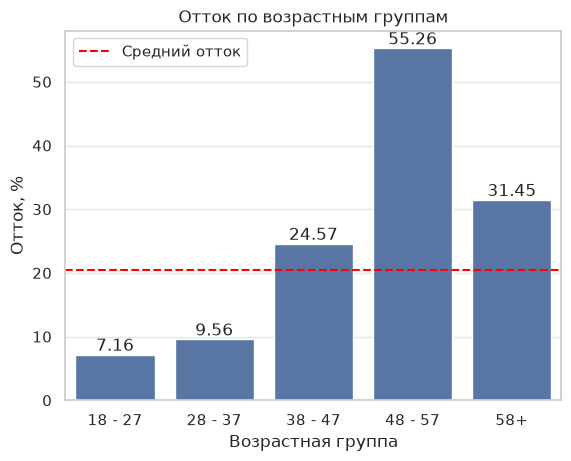

In [167]:
ax = sns.barplot(data=age_group_churn, x="age_group", y="churn_percent")
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.axhline(y=mean_churn, color="red", linestyle="--", label="Средний отток")
plt.legend()
plt.title("Отток по возрастным группам")
plt.xlabel("Возрастная группа")
plt.ylabel("Отток, %")
plt.savefig("../images/churn_by_group_age.png", dpi=150, bbox_inches="tight")
plt.show()

**График 2**

In [168]:
query = """
SELECT Age AS age, COUNT(*) AS clients, ROUND(AVG(Exited) * 100, 2) AS churn_percent
FROM df
GROUP BY Age
HAVING COUNT(*) >= 30
ORDER BY Age
"""
age_churn = duckdb.sql(query).df()

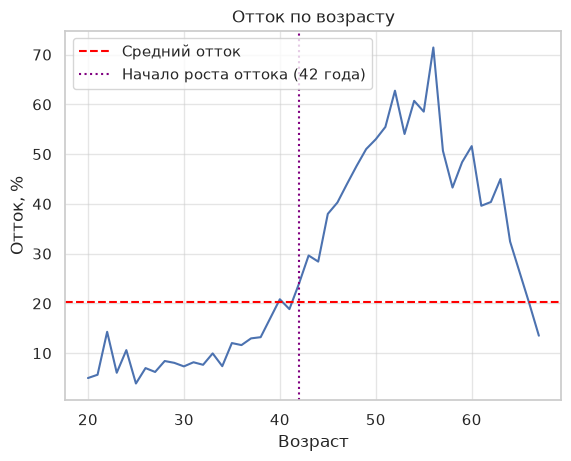

In [169]:
sns.lineplot(data=age_churn, x="age", y="churn_percent")
plt.axhline(y=mean_churn, color="red", linestyle="--", label="Средний отток")
plt.axvline(x=42, color="purple", linestyle=":", label="Начало роста оттока (42 года)")
plt.legend()
plt.title("Отток по возрасту")
plt.xlabel("Возраст")
plt.ylabel("Отток, %")
plt.savefig("../images/churn_by_age.png", dpi=150, bbox_inches="tight")
plt.show()

**График 3**

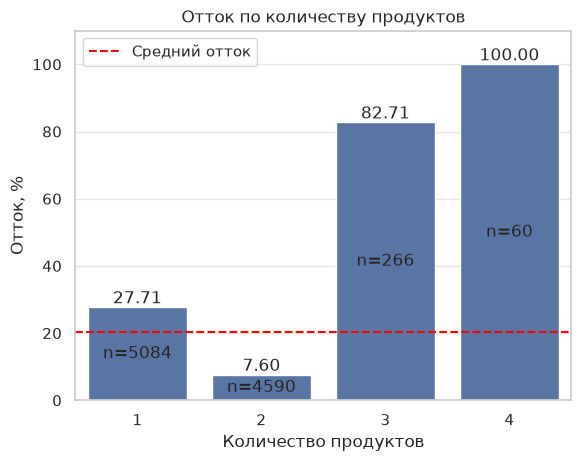

In [170]:
ax = sns.barplot(data=products_churn, x="products", y="churn_percent")
ax.bar_label(ax.containers[0], fmt="%.2f")
ax.bar_label(ax.containers[0], labels="n=" + products_churn.clients.astype(str), label_type="center")
plt.axhline(y=mean_churn, color="red", linestyle="--", label="Средний отток")
plt.legend()
plt.title("Отток по количеству продуктов")
plt.xlabel("Количество продуктов")
plt.ylabel("Отток, %")
plt.ylim(0, 110)
plt.savefig("../images/churn_by_num_of_products.png", dpi=150, bbox_inches="tight")
plt.show()

**График 4**

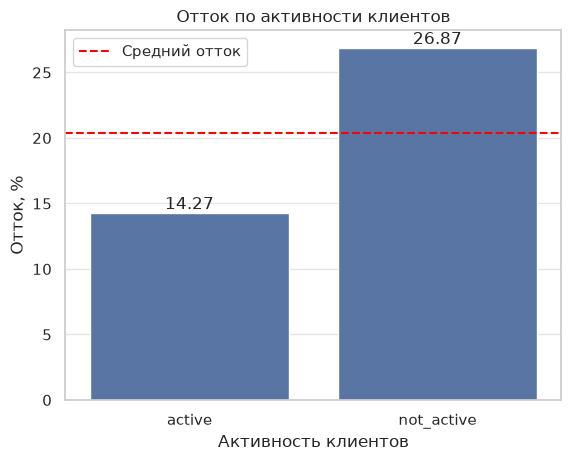

In [171]:
ax = sns.barplot(data=activity_churn, x="active", y="churn_percent")
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.axhline(y=mean_churn, color="red", linestyle="--", label="Средний отток")
plt.legend()
plt.title("Отток по активности клиентов")
plt.xlabel("Активность клиентов")
plt.ylabel("Отток, %")
plt.savefig("../images/churn_by_activity.png", dpi=150, bbox_inches="tight")
plt.show()

**График 5**

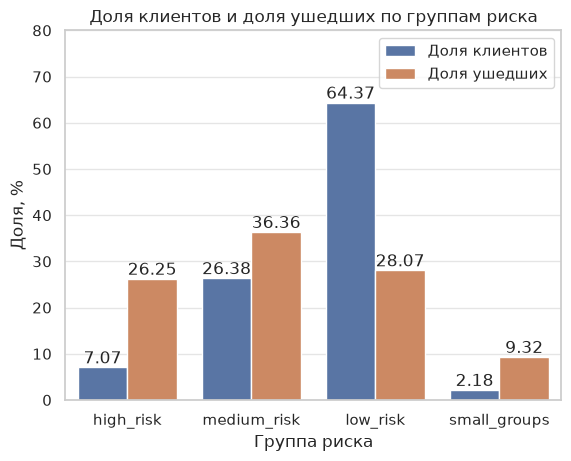

In [172]:
risk_churn_melt = risk_churn.melt(id_vars="risk_group", value_vars=["clients_share_percent", "churned_share_percent"], var_name="share_type", value_name="share_percent")
risk_churn_melt["share_type"] = risk_churn_melt["share_type"].map({"clients_share_percent": "Доля клиентов", "churned_share_percent": "Доля ушедших"})
ax = sns.barplot(data=risk_churn_melt, x="risk_group", y="share_percent", hue="share_type")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f")
plt.legend()
plt.title("Доля клиентов и доля ушедших по группам риска")
plt.xlabel("Группа риска")
plt.ylabel("Доля, %")
plt.ylim(0, 80)
plt.savefig("../images/share_by_risk_group.png", dpi=150, bbox_inches="tight")
plt.show()


**График 6**

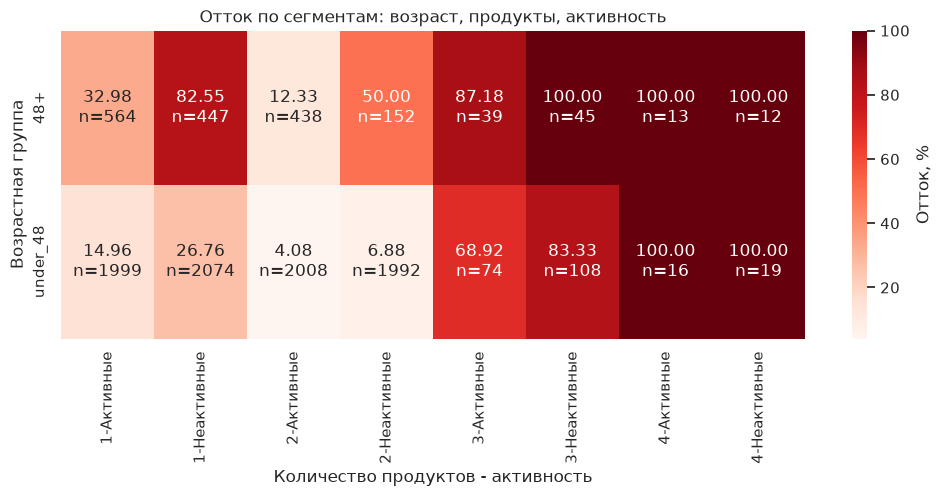

In [173]:
segments["active"] = segments["active"].map({0: "Неактивные", 1: "Активные"})
segments_wide = segments.pivot(index="age_group", columns=["products", "active"], values="churn_percent").sort_index(axis=1)
clients_wide = segments.pivot(index="age_group", columns=["products", "active"], values="clients").sort_index(axis=1)
labels = segments_wide.map("{:.2f}".format) + "\nn=" + clients_wide.astype(str)
plt.figure(figsize=(12, 4))
sns.heatmap(segments_wide, annot=labels, fmt="", cmap="Reds", cbar_kws={"label": "Отток, %"})
plt.title("Отток по сегментам: возраст, продукты, активность")
plt.xlabel("Количество продуктов - активность")
plt.ylabel("Возрастная группа")
plt.savefig("../images/churn_heatmap_segments.png", dpi=150, bbox_inches="tight")
plt.show()

**График 7**

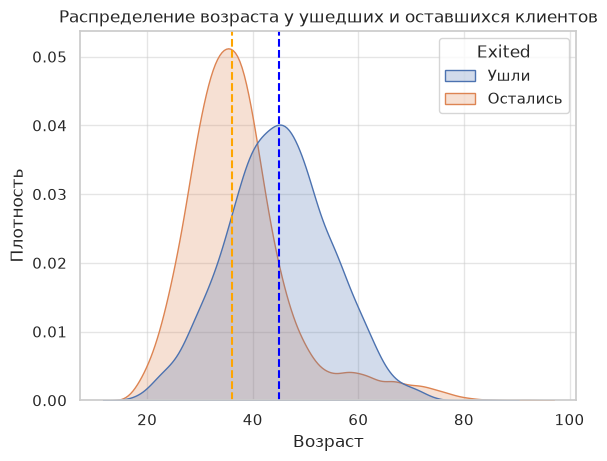

In [177]:
median_age_churned = df[df["Exited"] == 1]["Age"].median()
median_age_stayed = df[df["Exited"] == 0]["Age"].median()
sns.kdeplot(data=df, x="Age", hue=df["Exited"].replace({0: "Остались", 1: "Ушли"}), common_norm=False, fill=True)
plt.axvline(x=median_age_stayed, color="orange", linestyle="--", label="Медиана - остались")
plt.axvline(x=median_age_churned, color="blue", linestyle="--", label="Медиана - ушли")
plt.title("Распределение возраста у ушедших и оставшихся клиентов")
plt.xlabel("Возраст")
plt.ylabel("Плотность")
plt.savefig("../images/age_distribution_by_churn.png", dpi=150, bbox_inches="tight")
plt.show()